<a href="https://colab.research.google.com/github/caritopuya-ops/ProyectoP1_AA_GrupoD/blob/main/APORTES/Aporte_Angy_Soto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Primer Parcial — Aporte individual

**Estudiante:** Angy Belén Soto Lozano  
**Grupo:** D  
**Paralelo:** CDDEIA-ELNO-4-2  
**Responsabilidad:** Correlaciones, conclusiones y ética  
**Dataset:** `student-mat.csv` (395 estudiantes)



## Preparación común para ejecutar de forma independiente
Estas celdas de configuración y carga de datos son compartidas como apoyo técnico; la sección atribuible a este integrante comienza más abajo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV, LassoCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, confusion_matrix)
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

SEMILLA = 2026
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
print('Bibliotecas cargadas; semilla:', SEMILLA)

Bibliotecas cargadas; semilla: 2026


In [3]:
# Lectura local: en Google Colab también funciona si el CSV se sube al panel Archivos.
rutas = [Path('student-mat.csv'), Path('data/student-mat.csv'), Path('/content/student-mat.csv')]
ruta_csv = next((p for p in rutas if p.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError('Coloca student-mat.csv junto al notebook o en data/. No se modificó el dataset.')
df_original = pd.read_csv(ruta_csv, sep=',')
assert df_original.shape == (395, 33), f'Se esperaban 395 filas y 33 columnas, recibido: {df_original.shape}'
assert {'G1','G2','G3','absences','studytime'}.issubset(df_original.columns)
print('Archivo:', ruta_csv, '| Filas:', df_original.shape[0], '| Columnas:', df_original.shape[1])
display(df_original.head())

Archivo: student-mat.csv | Filas: 395 | Columnas: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## Trabajo asignado: Correlaciones, conclusiones y ética

**Revisión personal:** Interpretar las correlaciones y reescribir conclusiones con tus palabras. Verificar la dimensión ética y limitaciones.

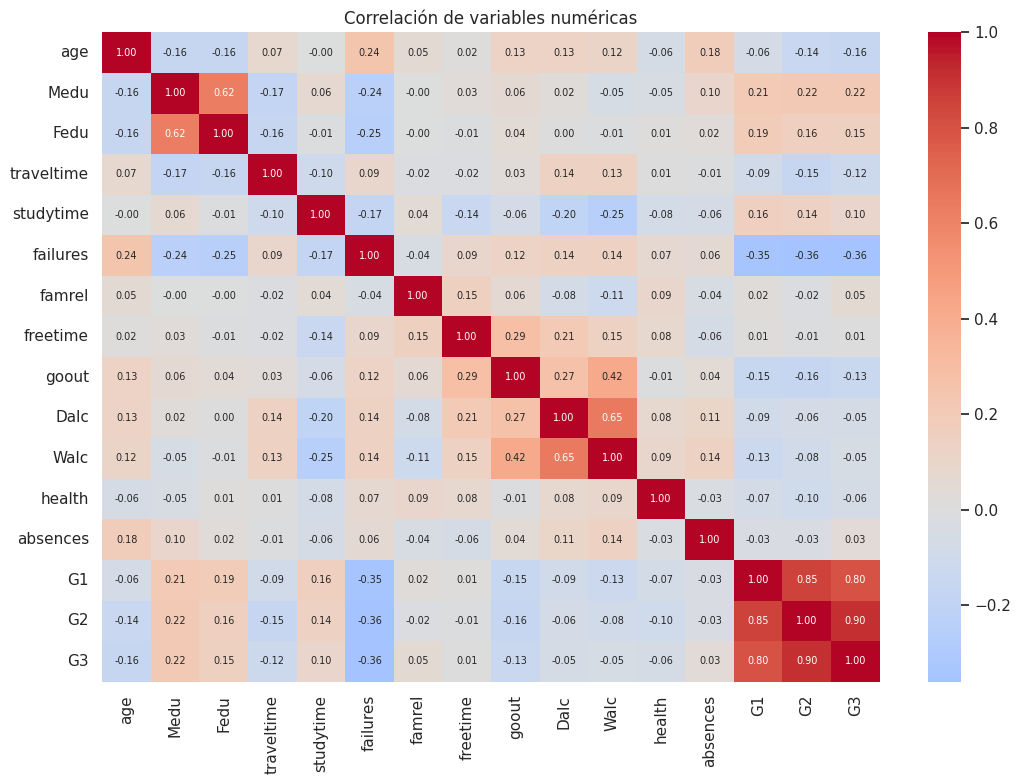

Correlaciones con G3:


,correlación
G2,0.905
G1,0.801
failures,-0.360
Medu,0.217
age,-0.162
Fedu,0.152
goout,-0.133
traveltime,-0.117
studytime,0.098
health,-0.061


G3 promedio según reprobaciones previas:


,mean,count
failures,,
False,11.25,312
True,7.27,83


In [4]:
correlaciones = df_original.select_dtypes(include=np.number).corr()
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlación de variables numéricas'); plt.tight_layout(); plt.show()
print('Correlaciones con G3:')
display(correlaciones['G3'].drop('G3').sort_values(key=abs, ascending=False).to_frame('correlación').round(3))
print('G3 promedio según reprobaciones previas:')
display(df_original.groupby(df_original['failures'] > 0)['G3'].agg(['mean','count']).round(2))

### Hallazgos principales del análisis exploratorio (EDA)

1. **Tasa de aprobación general:** La calificación final (`G3`) tiene un promedio de **10,42 sobre 20 puntos**, alcanzando la nota mínima de aprobación ($\ge 10$) aproximadamente el **67,1 %** de los estudiantes evaluados.
2. **Peso de las evaluaciones previas:** Las notas del segundo y primer período (`G2` con **r = 0,905** y `G1` con **r = 0,801**) presentan la correlación positiva más alta con la nota final; sin embargo, depender de ellas impide detectar riesgos al inicio del ciclo académico.
3. **Impacto del historial académico y entorno:** Los alumnos sin asignaturas reprobadas previamente (`failures = 0`) promedian **11,25 puntos** en `G3`, mientras que quienes registran reprobaciones anteriores bajan a **7,27 puntos** en promedio (una diferencia de casi 4 puntos), seguidos por la influencia positiva del nivel educativo de la madre (`Medu`, **r = 0,217**).

## Parte 5 — Conclusiones y reflexión ética

En nuestros modelos, las calificaciones previas (`G1` y `G2`) son las variables con mayor peso predictivo; sin embargo, al excluirlas para lograr una detección temprana (Modelo B), destacan las reprobaciones previas (`failures`), el nivel educativo de la madre (`Medu`), la aspiración de cursar estudios superiores (`higher`) y la frecuencia de salidas (`goout`). Entre las principales limitaciones del estudio se encuentran el tamaño reducido de la muestra (395 registros de dos escuelas portuguesas recopilados en 2008), lo que impide generalizar los resultados a otros contextos educativos, así como la capacidad explicativa moderada del Modelo B al no contar con evaluaciones parciales ni factores psicológicos o pedagógicos.

Desde el punto de vista ético, sería injusto y discriminatorio utilizar este modelo para negar becas o sancionar estudiantes, ya que penalizaría a jóvenes por características estructurales ajenas a su esfuerzo, como el sexo, el entorno familiar o el nivel educativo de sus padres, perpetuando brechas socioeconómicas. Por el contrario, su uso resulta muy valioso como sistema de alerta temprana para asignar tutorías voluntarias y acompañamiento psicopedagógico, priorizando un umbral que minimice los casos de riesgo no detectados. Finalmente, recomendamos a la institución actualizar periódicamente los datos con registros locales, auditar posibles sesgos algorítmicos y garantizar que cualquier decisión sobre el estudiante sea tomada por docentes y orientadores, nunca de forma automatizada.

## Registro de aporte personal

- **Qué revisé o cambié:** Ejecuté y validé la matriz de correlación de variables numéricas, redacté con palabras propias los tres hallazgos principales del análisis exploratorio (EDA) y estructuré las conclusiones y recomendaciones éticas de la Parte 5 en formato de ensayo cumpliendo la extensión solicitada.
- **Qué aprendí:** Comprendí la diferencia entre correlación y causalidad al analizar datos educativos, el riesgo de fuga de datos (*data leakage*) al depender de evaluaciones parciales y la importancia ética de usar modelos predictivos para brindar apoyo temprano sin discriminar a los estudiantes.
- **Qué resultado comprobé:** Verifiqué que `G2` tiene la mayor correlación con `G3` (**0,905**), `failures` presenta la correlación negativa más fuerte (**-0,360**) y los estudiantes sin reprobaciones previas promedian **11,25 puntos** frente a **7,27** de quienes sí reprobaron antes.

### Uso de herramientas
Se utilizaron herramientas de inteligencia artificial generativa (ChatGPT y Gemini) como apoyo técnico para estructurar el código de visualización de correlaciones y revisar la redacción de las conclusiones éticas; todos los resultados fueron ejecutados, verificados y redactados por la integrante.

### Referencias
Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. *Proceedings of the 5th Future Business Technology Conference (FUBUTEC 2008)*, 5–12.